# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Яцишин Роман'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 19      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 19: Кропивницький, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_кропивницький


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    # ----- ВАШ КОД: живий запит -----
    t0, b0 = time.time(), cache_bytes()           # 1) стан ДО виклику
    raw = getter()                                # 2) запит до Overpass
    tmp = path + '.tmp'
    clean(raw).to_parquet(tmp, index=False)       #    чистимо й зберігаємо
    os.replace(tmp, path)                         #    файл з'являється лише цілим
    g = gpd.read_parquet(path)                    #    повертаємо те саме, що дасть знімок
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),   # 3) вартість запиту
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 3)}
    return g

In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 96.8 км²


In [8]:
COST_LIVE = {k: dict(v) for k, v in COST.items()}

In [9]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 14766 | ребер 42680


In [10]:
json.dump(COST, open(os.path.join(OUT, 'cost_live.json'), 'w', encoding='utf-8'),
          ensure_ascii=False, indent=1)

### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [11]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.029,8.287
heritage,знімок,159,0.0,0.073,0.547
stations,знімок,6,0.0,0.031,0.343
amenities,знімок,190,0.0,0.06,0.149
мережа walk,знімок,57446,0.0,2.845,0.926


In [12]:
live = pd.DataFrame(json.load(open(os.path.join(OUT, 'cost_live.json'), encoding='utf-8'))).T
snap = pd.DataFrame(COST).T
display(snap)                                           # таблиця другого запуску

# контрольна ознака: усе зі знімків і нічого не передано
assert (snap['спосіб'] == 'знімок').all() and (snap['передано_МБ'] == 0).all()

cmp = pd.DataFrame({'живий_с': live['секунд'].astype(float),
                    'знімок_с': snap['секунд'].astype(float),
                    'передано_МБ': live['передано_МБ'].astype(float)})
cmp['у скільки разів швидше'] = (cmp['живий_с'] / cmp['знімок_с']).round(0)
display(cmp)

print('у скільки разів швидше загалом: %.0f' % (cmp['живий_с'].sum() / cmp['знімок_с'].sum()))
print('не передано мережею при повторному запуску: %.2f МБ' % cmp['передано_МБ'].sum())

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.029,8.287
heritage,знімок,159,0.0,0.073,0.547
stations,знімок,6,0.0,0.031,0.343
amenities,знімок,190,0.0,0.06,0.149
мережа walk,знімок,57446,0.0,2.845,0.926


,живий_с,знімок_с,передано_МБ,у скільки разів швидше
boundary,8.287,8.287,0.0,1.0
heritage,0.547,0.547,0.0,1.0
stations,0.343,0.343,0.0,1.0
amenities,0.149,0.149,0.0,1.0
мережа walk,0.926,0.926,0.0,1.0


у скільки разів швидше загалом: 1
не передано мережею при повторному запуску: 0.00 МБ


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [13]:
# ----- ВАШ КОД -----
# об'єднання двох сімейств тегів: historic АБО tourism
mask = heritage['historic'].notna() | heritage['tourism'].notna()

# лишаємо тільки ті, що мають непорожню назву
has_name = heritage['name'].notna() & (heritage['name'].astype(str).str.strip() != '')

cand = heritage[mask & has_name].copy().reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', len(cand))

# скільки відкинуто і чому (для звіту)
no_tag  = int((~mask).sum())
no_name = int((mask & ~has_name).sum())
print()
print('відкинуто всього       :', len(heritage) - len(cand))
print('  - без потрібних тегів :', no_tag)
print('  - без назви           :', no_name)

усього у шарі heritage : 159
підходять за тегами    : 159
з них мають name       : 130

відкинуто всього       : 29
  - без потрібних тегів : 0
  - без назви           : 29


In [14]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial              62
aircraft               6
citywalls              5
monument               3
technical_monument     1
yes                    1
fort                   1

=== tourism ===
tourism
attraction    34
museum         9
artwork        9
gallery        3
viewpoint      2

типи геометрії: {'Point': 89, 'Polygon': 36, 'LineString': 5}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [16]:
import re

metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

# ----- ВАШ КОД -----
def col(name):
    """Стовпець або порожній ряд, якщо такого тега в місті немає."""
    return cand[name] if name in cand.columns else pd.Series(None, index=cand.index, dtype='object')

# 1) стаття у Вікіпедії / Вікіданих: 0 або 1
cand['wiki'] = (col('wikidata').notna() | col('wikipedia').notna()).astype(int)

# 2) скільки мов має назва: лише справжні мовні колонки name:xx
#    (виключаємо name:etymology, name:pronunciation тощо)
lang_cols = [c for c in cand.columns if re.fullmatch(r'name:[a-z]{2,3}(-[A-Za-z]+)?', c)]
cand['n_lang'] = cand[lang_cols].notna().sum(axis=1)

# 3) призначений для відвідування: 0 або 1
cand['visit'] = col('tourism').isin(['museum', 'gallery', 'attraction', 'viewpoint']).astype(int)

# 4) має історичну природу: 0 або 1
cand['hist'] = col('historic').notna().astype(int)

# --- зведення до спільної шкали 0..1 ---
# n_lang: ранг серед тих, хто має хоча б одну переклад; нуль лишається нулем
r_lang = cand['n_lang'].rank(pct=True)
s_lang = np.where(cand['n_lang'] > 0, r_lang, 0.0)

# площа: найслабший сигнал, ранг лише серед полігонів
r_area = cand['area_m2'].rank(pct=True)
s_area = np.where(cand['area_m2'] > 0, r_area, 0.0)

W = {'wiki': 0.40, 'lang': 0.30, 'visit': 0.15, 'hist': 0.10, 'area': 0.05}

cand['score'] = (W['wiki']  * cand['wiki']
               + W['lang']  * s_lang
               + W['visit'] * cand['visit']
               + W['hist']  * cand['hist']
               + W['area']  * s_area)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мовних колонок:', len(lang_cols), '| з n_lang>0:', int((cand['n_lang'] > 0).sum()))
print('visit / hist :', int(cand['visit'].sum()), '/', int(cand['hist'].sum()))
print()
display(cand.nlargest(10, 'score')[['name', 'wiki', 'n_lang', 'visit', 'hist', 'area_m2', 'score']].round(2))

кандидатів   : 130
мають wiki   : 19
мовних колонок: 9 | з n_lang>0: 129
visit / hist : 48 / 79



,name,wiki,n_lang,visit,hist,area_m2,score
39,Л-410,1,2,1,1,0.00,0.92
90,Музей мистецтв,1,2,1,0,549.86,0.87
91,Обласний краєзнавчий музей,1,2,1,0,532.67,0.87
99,Фортеця Святої Єлисавети,1,9,0,1,344116.16,0.85
40,Ан-24РВ,1,1,1,1,0.00,0.77
41,Як-40,1,1,1,1,0.00,0.77
42,Іл-28,1,1,1,1,0.00,0.77
43,МіГ-21,1,1,1,1,0.00,0.77
80,Іл-76,1,1,1,1,0.00,0.77
4,Воїнам - Інтернаціоналістам,1,2,0,1,0.00,0.77



Caching the list of root modules, please wait!
(This will only be done once - type '%rehashx' to reset cache!)



### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [18]:
N_SMALL, N_LARGE = 10, 30

# ----- ВАШ КОД -----
# якщо кандидатів менше 30, беремо скільки є (і зазначте це у звіті)
N_LARGE = min(N_LARGE, len(cand))

top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)

# перетин рахуємо за індексами cand, а не за назвами:
# назви можуть повторюватись, індекс унікальний
idx_score = set(cand.nlargest(N_SMALL, 'score').index)
idx_area  = set(cand.nlargest(N_SMALL, 'area_m2').index)
overlap   = len(idx_score & idx_area)

print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за нашим критерієм': list(top10['name']),
                      'за площею': list(top_naive['name'])}))

# що саме спільне і чим відрізняються списки
common = cand.loc[sorted(idx_score & idx_area), 'name'].tolist()
print('\nспільні:', common if common else 'немає')

# скільки з топ-10 за площею взагалі мають статтю у Вікіпедії
print('топ-10 за площею, що мають wiki: %d з %d'
      % (int(cand.loc[list(idx_area), 'wiki'].sum()), N_SMALL))
print('топ-10 за нашим score, що мають wiki: %d з %d'
      % (int(cand.loc[list(idx_score), 'wiki'].sum()), N_SMALL))

перетин: 3 з 10


,за нашим критерієм,за площею
0,Л-410,Фортеця Святої Єлисавети
1,Музей мистецтв,Музей Ельворті
2,Обласний краєзнавчий музей,Музей мистецтв
3,Фортеця Святої Єлисавети,Автодром
4,Ан-24РВ,Обласний краєзнавчий музей
5,Як-40,Веселі гірки
6,Іл-28,Лабіринт
7,МіГ-21,Меморіальний музей М.Л.Кропивницького
8,Іл-76,"Галерея ""Єлисаветград"""
9,Воїнам - Інтернаціоналістам,Човники



спільні: ['Музей мистецтв', 'Обласний краєзнавчий музей', 'Фортеця Святої Єлисавети']
топ-10 за площею, що мають wiki: 4 з 10
топ-10 за нашим score, що мають wiki: 10 з 10


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [19]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

# ----- ВАШ КОД: виведіть знайдені пари з назвами -----
pairs = close_pairs(top_score, limit_m=60)
print('пар ближче 60 м у top_score:', len(pairs))

cols = ['name', 'historic', 'tourism', 'wiki', 'n_lang', 'area_m2', 'score']
rows = []
for i, j, d in pairs:
    a, b = top_score.iloc[i], top_score.iloc[j]
    rows.append({
        'відстань, м': round(d, 1),
        'A': a['name'], 'A тип': a['historic'] if pd.notna(a['historic']) else a['tourism'],
        'A wiki': int(a['wiki']), 'A площа': round(a['area_m2']),
        'B': b['name'], 'B тип': b['historic'] if pd.notna(b['historic']) else b['tourism'],
        'B wiki': int(b['wiki']), 'B площа': round(b['area_m2']),
        'позиції': '%d і %d' % (i + 1, j + 1),
    })

display(pd.DataFrame(rows) if rows else 'пар немає')

пар ближче 60 м у top_score: 5


,"відстань, м",A,A тип,A wiki,A площа,B,B тип,B wiki,B площа,позиції
0,26.8,Іл-28,aircraft,1,0,МіГ-21,aircraft,1,0,7 і 8
1,27.5,Першому трамваю м. Єлисаветграда,technical_monument,1,0,Перлина в центрі України,attraction,0,0,11 і 20
2,28.2,Як-40,aircraft,1,0,Іл-28,aircraft,1,0,6 і 7
3,28.7,"Історичний музей ""Євреї Єлисаветграда""",museum,1,0,Музей Г.Г.Нейгауза,museum,1,0,15 і 16
4,55.0,Як-40,aircraft,1,0,МіГ-21,aircraft,1,0,6 і 8


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [20]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 6
                   name  railway       building
0         Кропивницький  station            NaN
1                 Мирна     halt            NaN
2              Можарове     halt            NaN
3             Балашівка     halt            NaN
4                280 км     halt            NaN
5  Вокзал Кропивницький      NaN  train_station


In [21]:
# ----- ВАШ КОД -----
st = stations[stations['name'].notna()].copy()
# основний залізничний вокзал: станція, не зупинка; перевагу мають об'єкти зі статтею
if 'wikidata' in st.columns:
    st['_w'] = st['wikidata'].notna().astype(int)
else:
    st['_w'] = 0
st_main = st[st['railway'] == 'station'].sort_values('_w', ascending=False)

display(st_main[['name', 'railway', 'building', '_w']].head(10))

# оберіть рядок за назвою або візьміть перший
station = st_main.iloc[[0]]              # подвійні дужки: лишається таблицею з одним рядком
print('старт:', station['name'].iloc[0])

,name,railway,building,_w
0,Кропивницький,station,NaN,1


старт: Кропивницький


In [22]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 14766 вузлів, 42213 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [24]:
def check_snap(points, ids, dist, label):
    # ----- ВАШ КОД -----
    n_pts = len(points)
    n_nodes = len(set(ids))
    print('=== %s ===' % label)
    print('точок: %d | різних вузлів: %d' % (n_pts, n_nodes))
    print('відстань точка → вузол: медіана %.1f м, максимум %.1f м'
          % (np.median(dist), np.max(dist)))

    if n_nodes < n_pts:
        print('УВАГА: точки злиплись на спільних вузлах:')
        ids_s = pd.Series(ids)
        for node, grp in ids_s.groupby(ids_s):
            if len(grp) > 1:
                names = [str(points['name'].iloc[i]) for i in grp.index]
                print('  вузол %s: %s' % (node, ' | '.join(names)))
    else:
        print('усі точки на різних вузлах')

    # найдальші від мережі точки: їхній шлях буде найменш точним
    far = np.argsort(dist)[::-1][:3]
    print('найдальші від вузла:', ['%s (%.0f м)' % (points['name'].iloc[i], dist[i]) for i in far])
    print()

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [25]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    # ----- ВАШ КОД: матриця прямих віддалей у метрах -----
    p = points.to_crs(32635).geometry          # метрична CRS, не градуси
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    # ----- ВАШ КОД: медіана відношення дорога / пряма, по скінченних парах -----
    off = ~np.eye(len(D), dtype=bool)          # без діагоналі (там 0/0)
    ok = off & np.isfinite(D) & (E > 0)        # скінченні дорожні віддалі, ненульові прямі
    return float(np.median(D[ok] / E[ok]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [26]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

=== мала задача ===
точок: 11 | різних вузлів: 10
відстань точка → вузол: медіана 20.1 м, максимум 87.0 м
УВАГА: точки злиплись на спільних вузлах:
  вузол 3522704155: Як-40 | Іл-28
найдальші від вузла: ['Іл-76 (87 м)', 'МіГ-21 (71 м)', 'Іл-28 (55 м)']

матриця за 2.444 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.22


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [27]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    # ----- ВАШ КОД -----
    k = len(D)
    tour = [0]
    unvisited = set(range(1, k))
    while unvisited:
        cur = tour[-1]
        nxt = min(unvisited, key=lambda j: D[cur, j])   # найближча невідвідана
        tour.append(nxt)
        unvisited.remove(nxt)
    tour.append(0)                                      # повернення на старт
    return tour

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    # ----- ВАШ КОД -----
    best = list(tour)
    best_len = tour_length(D, best)
    improved = True
    while improved:
        improved = False
        # перша (0) і остання точки — старт і фініш, їх не чіпаємо
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                cand = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                L = tour_length(D, cand)
                if L < best_len - 1e-9:                 # строго коротше
                    best, best_len = cand, L
                    improved = True
    return best

In [28]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [29]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [30]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,13093,2.18
2-opt,12814,0.00
Held-Karp (точний),12814,0.00



оптимальний порядок:
   0. СТАРТ: Кропивницький
   1. Ан-24РВ
   2. Іл-28
   3. Як-40
   4. Іл-76
   5. МіГ-21
   6. Л-410
   7. Обласний краєзнавчий музей
   8. Воїнам - Інтернаціоналістам
   9. Фортеця Святої Єлисавети
  10. Музей мистецтв
  11. СТАРТ: Кропивницький

довжина: 12.81 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [31]:
# ----- ВАШ КОД: таблиця зростання -----
rows = []
for n in (11, 16, 21, 26, 31):
    cells = 2 ** (n - 1) * (n - 1)          # розмір таблиці dp: 2^(n-1) підмножин × (n-1) кінцевих точок
    gb = cells * 8 / 1e9                    # 8 байтів на клітину (float64)
    ops = 2 ** (n - 1) * (n - 1) ** 2       # орієнтовна кількість операцій
    rows.append({'n (з вокзалом)': n, 'клітин': cells, 'ГБ': gb, 'операцій': ops})

grow = pd.DataFrame(rows).set_index('n (з вокзалом)')
pd.options.display.float_format = '{:,.4f}'.format
display(grow)
pd.reset_option('display.float_format')

,клітин,ГБ,операцій
n (з вокзалом),,,
11,10240,0.0001,102400
16,491520,0.0039,7372800
21,20971520,0.1678,419430400
26,838860800,6.7109,20971520000
31,32212254720,257.6980,966367641600


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [32]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

=== велика задача ===
точок: 31 | різних вузлів: 30
відстань точка → вузол: медіана 20.1 м, максимум 606.3 м
УВАГА: точки злиплись на спільних вузлах:
  вузол 3522704155: Як-40 | Іл-28
найдальші від вузла: ['Танк Т-34 (606 м)', 'Іл-76 (87 м)', 'МіГ-21 (71 м)']

коефіцієнт обходу: 1.23
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    43548 м
2-opt            :    37573 м  за 0.066 с  (коротше на 13.7%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

In [34]:
import h3
from shapely.geometry import Polygon
import branca.colormap as cm

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

# ----- ВАШ КОД -----
# 1) кожному кандидату — його комірка H3 (за репрезентативною точкою, бо бувають полігони)
pts_c = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in pts_c]   # (lat, lng)

# 2) щільність: скільки пам'яток у кожній комірці
dens = cand.groupby('h3').size().rename('n').reset_index()

# 3) комірки → полігони. cell_to_boundary дає (lat, lng), а Polygon чекає (lng, lat)
hexes = gpd.GeoDataFrame(
    dens,
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in dens['h3']],
    crs='EPSG:4326')

# 4) у скількох комірках половина всіх пам'яток (для питання до звіту)
srt = dens['n'].sort_values(ascending=False).reset_index(drop=True)
half = int((srt.cumsum() < srt.sum() / 2).sum() + 1)
print('кандидатів: %d | комірок із пам\'ятками: %d' % (len(cand), len(dens)))
print('половина (%d) пам\'яток зосереджена у %d комірках (%.0f%% зайнятих)'
      % (srt.sum() / 2, half, 100 * half / len(dens)))
print('максимум в одній комірці:', int(srt.iloc[0]))

# 5) карта: щільність + межа міста + точки маршруту
center = [hexes.geometry.centroid.y.mean(), hexes.geometry.centroid.x.mean()]
fmap = folium.Map(location=center, zoom_start=14, tiles=None)
folium.TileLayer(tiles=BASEMAP.build_url(), attr=BASEMAP.html_attribution,
                 name='підложка').add_to(fmap)

cmap = cm.LinearColormap(['#ffffb2', '#fd8d3c', '#bd0026'],
                         vmin=1, vmax=max(2, int(dens['n'].max())),
                         caption='пам\'яток у комірці H3 (рівень %d)' % H3_RES)
cmap.add_to(fmap)

folium.GeoJson(
    hexes.to_json(),
    name='щільність',
    style_function=lambda f: {'fillColor': cmap(f['properties']['n']),
                              'color': '#555', 'weight': 0.6, 'fillOpacity': 0.65},
    tooltip=folium.GeoJsonTooltip(fields=['n'], aliases=['пам\'яток:'])
).add_to(fmap)

folium.GeoJson(gpd.GeoSeries([poly], crs='EPSG:4326').to_json(), name='межа міста',
               style_function=lambda f: {'fill': False, 'color': '#1f3a93', 'weight': 3}
               ).add_to(fmap)

for k, (nm, g) in enumerate(zip(pts30['name'], pts30.geometry)):
    folium.CircleMarker([g.y, g.x], radius=7 if k == 0 else 4,
                        color='black', fill=True,
                        fill_color='#2ecc71' if k == 0 else '#3498db',
                        fill_opacity=1, tooltip=str(nm)).add_to(fmap)

folium.LayerControl().add_to(fmap)
fmap.save('lr5_щільність.html')
import webbrowser, os
webbrowser.open('file://' + os.path.abspath('lr5_щільність.html'))

середнє ребро комірки: 201 м
кандидатів: 130 | комірок із пам'ятками: 54
половина (65) пам'яток зосереджена у 9 комірках (17% зайнятих)
максимум в одній комірці: 15


True

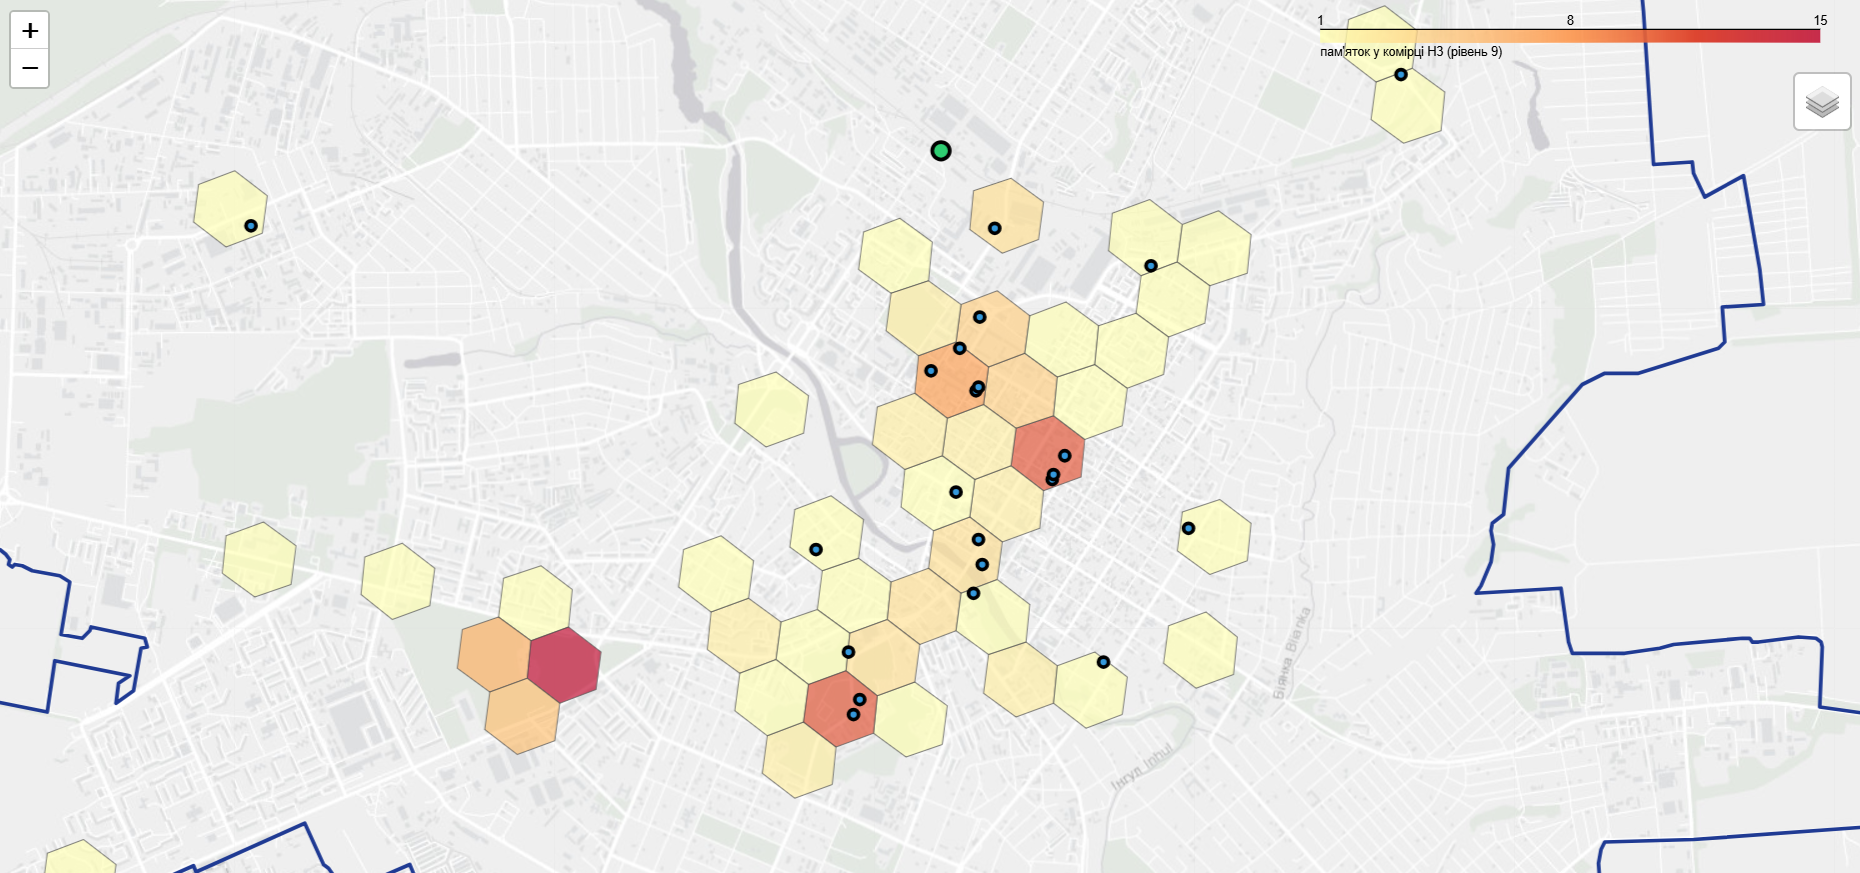

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [35]:
# ----- ВАШ КОД -----
# 1) точки маршруту (вокзал + 30 пам'яток) у метрах
pm = pts30.to_crs(32635).reset_index(drop=True)

# 2) заклади: лишаємо потрібні стовпці, кожен об'єкт зводимо до точки,
#    бо частина закладів в OSM є полігонами (будівлями)
am = amenities.reset_index()[['amenity', 'name', 'geometry']].to_crs(32635)
am['geometry'] = am.geometry.representative_point()
am = am.rename(columns={'amenity': 'тип', 'name': 'заклад'})

# 3) найближчий заклад до кожної точки; відстань записується в метрах
near = gpd.sjoin_nearest(pm, am, how='left', distance_col='відстань_м')

# за однакової відстані sjoin_nearest повертає кілька рядків: лишаємо один
near = near[~near.index.duplicated(keep='first')]

res = near[['name', 'тип', 'заклад', 'відстань_м']].rename(columns={'name': 'точка маршруту'})
res['відстань_м'] = res['відстань_м'].round(0)
display(res.reset_index(drop=True))

print('медіана відстані до найближчого закладу: %.0f м' % res['відстань_м'].median())
print('максимум: %.0f м (%s)' % (res['відстань_м'].max(),
      res.loc[res['відстань_м'].idxmax(), 'точка маршруту']))
print('закладів без назви:', int(res['заклад'].isna().sum()))
print('типи найближчих закладів:', res['тип'].value_counts().to_dict())

,точка маршруту,тип,заклад,відстань_м
0,СТАРТ: Кропивницький,toilets,NaN,72.0
1,Л-410,cafe,"Магазин-кафе ""Бістро""",64.0
2,Музей мистецтв,cafe,Кав'ярня Марракеш,33.0
3,Обласний краєзнавчий музей,restaurant,Sorrento,67.0
4,Фортеця Святої Єлисавети,restaurant,Турист,411.0
5,Ан-24РВ,restaurant,Rebro Grill and Bar,187.0
6,Як-40,restaurant,Rebro Grill and Bar,251.0
7,Іл-28,restaurant,Rebro Grill and Bar,277.0
8,МіГ-21,restaurant,Rebro Grill and Bar,303.0
9,Іл-76,restaurant,Rebro Grill and Bar,563.0


медіана відстані до найближчого закладу: 201 м
максимум: 1483 м (Танк Т-34)
закладів без назви: 1
типи найближчих закладів: {'cafe': 18, 'restaurant': 12, 'toilets': 1}


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [37]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

# ----- ВАШ КОД: folium.Map(..., tiles=BASEMAP), дві PolyLine, маркери з номерами -----
tour = op30                                   # маршрут 2-opt на 30 точках (індекси рядків pts30)

road_line = route_coords(tour, ids30)         # справжній шлях по ребрах графа
straight_line = [(float(pts30.geometry.y.iloc[i]), float(pts30.geometry.x.iloc[i])) for i in tour]

# числа для підпису і звіту
L_road  = tour_length(D30, tour)              # дорогою
L_str   = tour_length(E30, tour)              # по прямих відрізках
print('по прямих відрізках: %.2f км | дорогою: %.2f км | відношення: %.2f'
      % (L_str / 1000, L_road / 1000, L_road / L_str))

c = pts30.geometry
fmap = folium.Map(location=[float(c.y.mean()), float(c.x.mean())], zoom_start=14, tiles=None)
folium.TileLayer(tiles=BASEMAP.build_url(), attr=BASEMAP.html_attribution,
                 name='підложка').add_to(fmap)

# 1) прямі відрізки: червоний пунктир, тонкий
fg_s = folium.FeatureGroup(name='прямі відрізки (%.2f км)' % (L_str / 1000)).add_to(fmap)
folium.PolyLine(straight_line, color='#e74c3c', weight=2, opacity=0.9,
                dash_array='6,8').add_to(fg_s)

# 2) маршрут по ребрах графа: синя суцільна, товста
fg_r = folium.FeatureGroup(name='маршрут по ребрах (%.2f км)' % (L_road / 1000)).add_to(fmap)
folium.PolyLine(road_line, color='#1f3a93', weight=5, opacity=0.85).add_to(fg_r)

# 3) маркери з номерами порядку обходу (0 — вокзал)
fg_m = folium.FeatureGroup(name='точки').add_to(fmap)
for step, i in enumerate(tour[:-1]):
    lat, lon = straight_line[step]
    color = '#2ecc71' if step == 0 else '#ffffff'
    html = ('<div style="background:%s;border:2px solid #1f3a93;border-radius:50%%;'
            'width:24px;height:24px;line-height:20px;text-align:center;'
            'font-size:12px;font-weight:bold;color:#1f3a93">%s</div>'
            % (color, 'С' if step == 0 else step))
    folium.Marker([lat, lon], icon=folium.DivIcon(html=html, icon_size=(24, 24),
                                                  icon_anchor=(12, 12)),
                  tooltip='%d. %s' % (step, pts30['name'].iloc[i])).add_to(fg_m)

folium.LayerControl(collapsed=False).add_to(fmap)
fmap.save('lr5_маршрут.html')
print('збережено lr5_маршрут.html')

import webbrowser
webbrowser.open('file://' + os.path.abspath('lr5_маршрут.html'))

по прямих відрізках: 31.04 км | дорогою: 37.57 км | відношення: 1.21
збережено lr5_маршрут.html


True

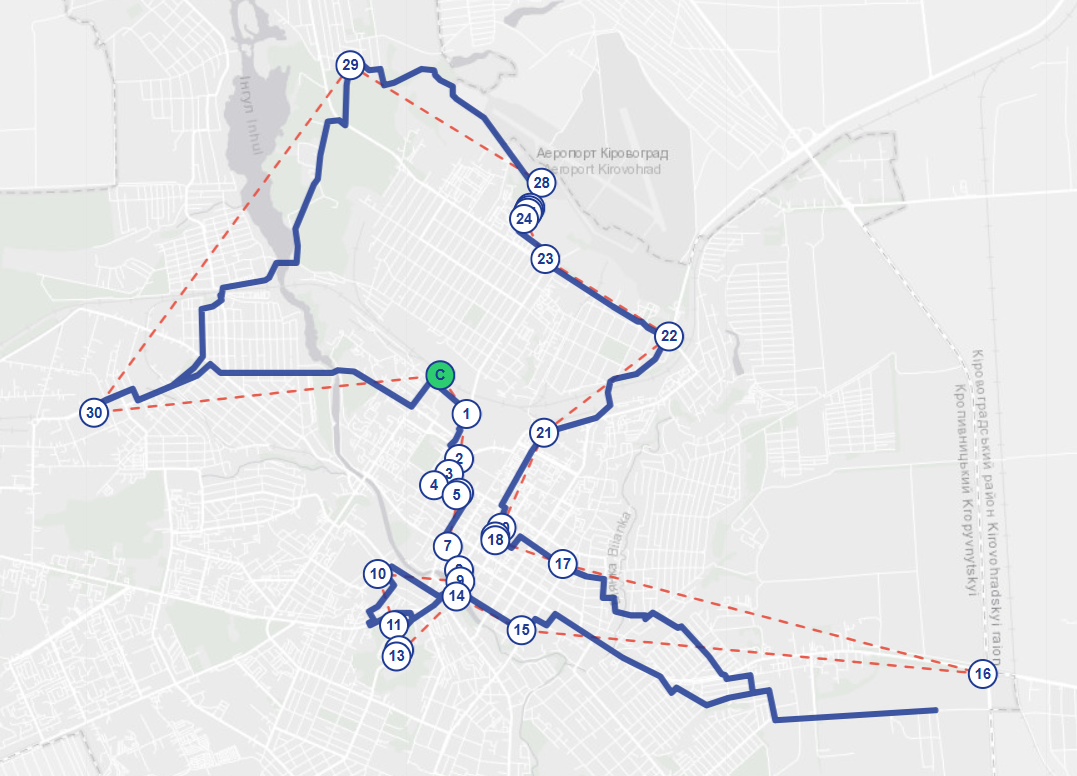

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [38]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.9 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [39]:
REPORT = '''
1. Відбір. Із 159 об'єктів шару heritage відкинуто 29 (18%), лишилось 130. Правило:
(historic АБО tourism заповнені) І name непорожній. За тегами відкинуто 0 із 159, бо
запит до Overpass уже вибирав лише historic=* і tourism зі списку (museum, attraction,
gallery, artwork, viewpoint); усі 29 відкинуто за відсутністю name. Взято об'єднання,
а не перетин: музей у сучасній будівлі має лише tourism, руїни лише historic.
Кандидатів 130 > 30, тож N_LARGE не зменшувався. Без пояснень цей фільтр я б
замовнику не віддав: безіменний об'єкт може бути справжньою пам'яткою, яку не
підписали в OSM, тобто ми губимо його через неповноту даних, а не малу цінність.

2. Рейтинг. score = 0.40·wiki + 0.30·n_lang + 0.15·visit + 0.10·hist + 0.05·area.
Серед 130 кандидатів wiki мають 19, visit 48, historic заповнений у 79. wiki —
найсильніший сигнал (сторонні люди визнали об'єкт вартим опису). n_lang (ранг
rank(pct=True)) — перекладають те, що шукають іноземці, але він частково дублює wiki,
тому вага менша; 129 зі 130 об'єктів мають мовну колонку (знайдено 9 name:xx), тож
розрізняє слабко. visit — призначений для відвідування, але таких мало, вага помірна.
hist є майже в 60% кандидатів, розрізняє слабко. area — найслабший сигнал (склад може
бути більшим за палац). Ваги підібрані експертно, не калібровані, тож це припущення.

3. Два рейтинги. У топ-10 за score і за площею збіглося 3 із 10: Музей мистецтв,
Обласний краєзнавчий музей, Фортеця Святої Єлисавети. У топ-10 за площею wiki мають
4, за score — 10 із 10 (частково тавтологія: wiki входить у формулу з вагою 0.40).
Топ за площею містить Автодром, Веселі гірки, Лабіринт і Човники — об'єкти парку
розваг, не пам'ятки. Площа вибирає великі споруди, а не цінні. Ті самі дані й код
без помилок дають різні «найкращі»: слово не має сенсу без уточнення критерію, а
критерій відбору — змістовне рішення, не технічна деталь.

4. Обхід і прив'язка. Коефіцієнт обходу 1.22 (мала задача) і 1.23 (велика), на карті
1.21 (31.04 км по прямих, 37.57 км дорогою): нижня межа типового діапазону 1.2–1.6,
бо між точками немає непрохідних перешкод. Рівно 1.0 немає, отже матриці різні.
Недосяжних пар 0, асиметрія 0 м (пішохідна мережа без односторонніх ділянок).
Контрольну ознаку (стільки ж вузлів, скільки точок) порушено: 11 точок зайняли 10
вузлів, 31 — 30. Як-40 та Іл-28 (28.2 м одна від одної) сіли на вузол 3522704155, тож
віддаль між ними нуль. Відстань точка→вузол: медіана 20.1 м, максимум 87.0 м (мала)
і 606.3 м (велика, Танк Т-34: на карті лінія не доходить до маркера, тож довжина
маршруту трохи занижена).

5. Методи. Мала задача: найближчий сусід 13093 м, оптимум (Held–Karp) 12814 м,
тобто гірший на 2.18%; 2-opt = 12814 м (0.00%) — знайшов точний розв'язок. На 30 точках 2-opt скоротив маршрут відносно
найближчого сусіда на 13.7% (43548 → 37573 м) за 0.066 с: жадібний метод на малій
задачі помилявся мало, на великій втрачає набагато більше.

6. Точний розв'язок. Для n = 31 (30 пам'яток + вокзал) таблиця Held–Karp має
2^30·30 ≈ 3.2·10^10 клітин, при 8 байтах це ≈ 258 ГБ лише для dp (стільки ж для par).
Для порівняння: n = 21 — 0.17 ГБ, n = 26 — 6.7 ГБ; стани подвоюються з кожною точкою.
Час (~10^12 операцій) теж великий, але жорстка межа — пам'ять.

7. Дані.
(а) 29 об'єктів без name відкинуто; лише 19 зі 130 мають wiki, тож рейтинг спирається
на малу підмножину.
(б) Шість із топ-10 — пам'ятники літакам (Л-410, Ан-24РВ, Як-40, Іл-28, МіГ-21, Іл-76):
точки (площа 0) з wiki, що стоять поруч, по суті одне місце. 
(в) 5 пар ближче 60 м: Іл-28/МіГ-21 (26.8 м), Як-40/Іл-28 (28.2), Як-40/МіГ-21 (55.0),
«Першому трамваю»/«Перлина в центрі України» (27.5), Історичний музей «Євреї
Єлисаветграда»/Музей Г.Г.Нейгауза (28.7). Усі лишено: це різні об'єкти (експонати та
сусідні музеї), не дублікати. Недолік: літаки дають фактично одну зупинку.
(г) H3 (ребро 201 м): 130 кандидатів у 54 комірках, половина (65) — у 9 комірках (17%
зайнятих), максимум 15 в одній. Найгустіша комірка лежить на краю міста й не містить
жодної точки топ-30. Пам'ятки скупчені в смузі центру, тож
маршрут — щільне ядро й довгі переходи до віддалених об'єктів.
(д) Найближчий заклад (по прямій): медіана 201 м, максимум 1483 м (Танк Т-34); 18
кафе, 12 ресторанів, 1 туалет (найближчий до вокзалу, 72 м, без назви). Дорогою було б
більше приблизно в 1.2 раза. Помилки тегів: «Vianor» позначено cafe, імовірно це
шиномонтаж; для п'яти літаків найближчий заклад один — «Rebro Grill and Bar».
(е) Маршрут: 31.04 км по прямих, 37.57 км дорогою (відношення 1.21, +21%). Точки 16,
29, 30 віддалені на кілька км і дають значну частину довжини; у центрі точки стоять за
кілька десятків метрів.

Декларація про використання ШІ:
Користувався Claude для пояснення завдань, коду кроків 2–9 і чернетки звіту.
Перевірка: код запускав; контрольні перевірки (структура маршрутів, 2-opt не гірший за
вхідний, Held–Karp не гірший за 2-opt) пройшли; коефіцієнт обходу в типовому діапазоні;
порушення ознаки прив'язки (злиплі вузли) виявлено й описано. Числа взято зі своїх
виводів, ваги обґрунтовано самостійно.
'''
print(REPORT)


1. Відбір. Із 159 об'єктів шару heritage відкинуто 29 (18%), лишилось 130. Правило:
(historic АБО tourism заповнені) І name непорожній. За тегами відкинуто 0 із 159, бо
запит до Overpass уже вибирав лише historic=* і tourism зі списку (museum, attraction,
gallery, artwork, viewpoint); усі 29 відкинуто за відсутністю name. Взято об'єднання,
а не перетин: музей у сучасній будівлі має лише tourism, руїни лише historic.
Кандидатів 130 > 30, тож N_LARGE не зменшувався. Без пояснень цей фільтр я б
замовнику не віддав: безіменний об'єкт може бути справжньою пам'яткою, яку не
підписали в OSM, тобто ми губимо його через неповноту даних, а не малу цінність.

2. Рейтинг. score = 0.40·wiki + 0.30·n_lang + 0.15·visit + 0.10·hist + 0.05·area.
Серед 130 кандидатів wiki мають 19, visit 48, historic заповнений у 79. wiki —
найсильніший сигнал (сторонні люди визнали об'єкт вартим опису). n_lang (ранг
rank(pct=True)) — перекладають те, що шукають іноземці, але він частково дублює wiki,
тому вага менша; 